<a href="https://colab.research.google.com/github/mshmatsuda/python-100-knocks/blob/main/100knocks_083_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. 動画データも「NumPy配列の塊」

ノック81で、1枚の画像は (縦, 横, 3色) の3次元配列だと学びました。<br>
動画は、その画像（フレーム）がパラパラマンガのように時間軸に沿って何枚も重なったものです。<br>
<br>
住所のイメージで言うと、動画はさらにもう1つ住所が増えて4次元配列のような構造になります。
-  [何秒目のフレームか][縦のY座標][横のX座標][色データ] ＝ 1つの数字！
<br>ノック83では、このパラパラマンガを1枚ずつ分解して読み込む処理を行います。

## 2. Colab専用の「動画読み込み＆確認コード」

書籍にある「while ループと cv2.imshow」を使うコードの代わりに、Colabでは「最初の数フレームだけを画像として切り出して表示する」という方法を取るのが一番スマートでエラーになりません。<br><br>
以下のコードをColabのセルに貼り付けて実行してみてください。
<br><br>
【python】<br>
import cv2<br>
import matplotlib.pyplot as plt<br>
<br>
　# 1. 動画ファイルの読み込み（パスは環境に合わせて変更してください）<br>
　# ※ 100本ノックのデータフォルダ構成に合わせています<br><br>
video_path = "sample_code/chapter_8/movie.mp4" 　# 動画の保存場所にパスを通す<br>
cap = cv2.VideoCapture(video_path)<br><br>
　# 2. 動画が正しく開けたか確認<br>
if not cap.isOpened():<br>
　　print("動画ファイルが開けませんでした。パスを確認してください。")<br>
else:<br>
　　print("動画の読み込みに成功しました！")<br><br>
    
　　# 3. 最初の3フレーム（3枚の画像）だけをパラパラマンガから取り出して表示してみる<br>
　　for i in range(3):<br>
　　　　ret, frame = cap.read()　# 1枚分の画像を読み込む（retは成功フラグ、frameが画像データ）<br>
<br>        
　　　　if ret:<br>
　　　　　　# 読み込んだフレーム（画像）の型と形（shape）を確認<br>
　　　　　　print(f"--- フレーム {i} ---")<br>
　　　　　　print(f"データの型: {type(frame)}")<br>
　　　　　　print(f"データの形 (shape): {frame.shape}") 　# ここで(縦, 横, 3)の3次元配列が出る<br>
<br>            
　　　　　　# OpenCVのBGRから、matplotlib用のRGBに変換してColab上に表示<br>
<br>
　　　　　　frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)<br>
　　　　　　plt.figure(figsize=(6, 4))<br>
　　　　　　plt.imshow(frame_rgb)<br>
　　　　　　plt.title(f"Frame {i}")<br>
　　　　　　plt.axis('off')<br>
　　　　　　plt.show()<br>
　　　　else:<br>
　　　　　　print(f"フレーム {i} の読み込みに失敗しました。")<br>
　　　　　　break<br>
<br>
　　# 4. 最後に必ず動画ファイルを解放する（超重要！）<br>
cap.release()<br>

## 3. コードの注目ポイント
- cap = cv2.VideoCapture(パス)<br>
動画を読み込むための「装置」を作っています。<br><br>
- ret, frame = cap.read()<br>
ここが一番の核心です！動画から「次の1枚」をパッと抜き出します。<br>
• ret：次の枚数がちゃんとあったか？（True / False）<br>
• frame：抜き出した1枚の画像データ。中身はノック81と全く同じ3次元配列 (720, 1280, 3) です。<br>

- cap.release()<br>
動画ファイルを「使い終わったので閉じます」という合図です。<br>
これを忘れるとColabの裏で動画ファイルが開きっぱなしになり、次にコードを動かしたときにエラーの原因になります。<br>
<br>
まずはこのコードで、動画から1枚ずつの画像データ（3次元配列）が順々に取り出せる感覚を掴んでみてください！<br>


Mounted at /content/drive
動画の読み込みに成功しました！
--- フレーム 0 ---
データの型: <class 'numpy.ndarray'>
データの形 (shape): (1440, 1920, 3)


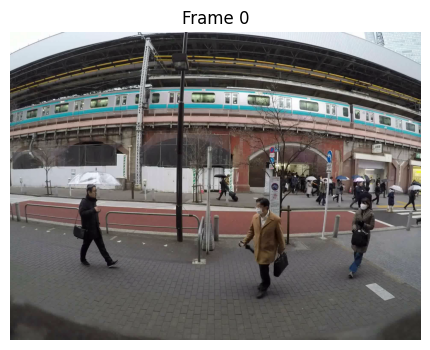

--- フレーム 1 ---
データの型: <class 'numpy.ndarray'>
データの形 (shape): (1440, 1920, 3)


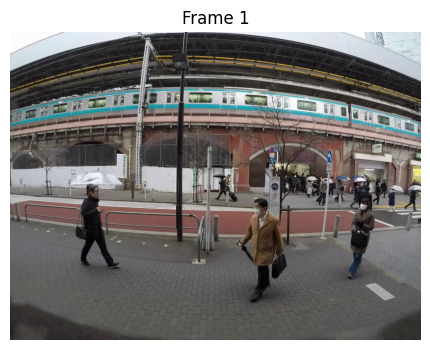

--- フレーム 2 ---
データの型: <class 'numpy.ndarray'>
データの形 (shape): (1440, 1920, 3)


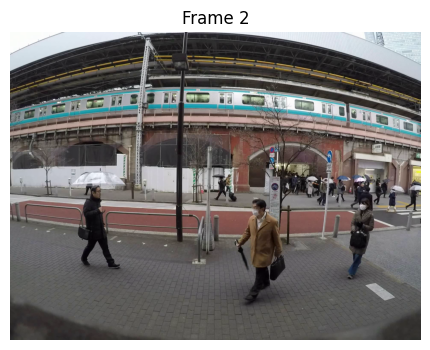

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# 9章のデータがあるフォルダへ移動する
import os
os.chdir('/content/drive/MyDrive/Colab Notebooks/16_python-100-knocks/100knocks_download/サンプルコード_20201021/9章/')

import cv2
import matplotlib.pyplot as plt

# 動画の保存場所にパスを通す
video_path = "mov/mov01.avi"
cap = cv2.VideoCapture(video_path)

# 動画が正しく開けたか確認
if not cap.isOpened():
  print("動画ファイルが開けませんでした。パスを確認してください。")
else:
  print("動画の読み込みに成功しました！")

# 最初の3フレーム（3枚の画像）だけをパラパラマンガから取り出して表示してみる
# 1枚分の画像を読み込む（retは成功フラグ、frameが画像データ）

  for i in range(3):
    ret, frame = cap.read()

# 読み込んだフレーム（画像）の型と形（shape）を確認
    if ret:
      print(f"--- フレーム {i} ---")
      print(f"データの型: {type(frame)}")
      print(f"データの形 (shape): {frame.shape}")
# ここで(縦, 横, 3)の3次元配列が出る


# OpenCVのBGRから、matplotlib用のRGBに変換してColab上に表示

      frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
      plt.figure(figsize=(6, 4))
      plt.imshow(frame_rgb)
      plt.title(f"Frame {i}")
      plt.axis('off')
      plt.show()
    else:
      print(f"フレーム {i} の読み込みに失敗しました。")
      break

# 最後に必ず動画ファイルを解放する（超重要！）
cap.release()

はい、その通りです！ <br>
Google ColaboratoryでOpenCVを使って画像を表示したい場合、標準の cv2.imshow の代わりに、Colab専用に用意されている cv2_imshow をインポートして使うのが正解です。<br>
<br>
cv2_imshow を使えば、matplotlib を使わずに、OpenCVで読み込んだ画像（NumPy配列）をそのままColabの画面上にパッと表示させることができます。<br>
<br>
先ほどのコードを cv2_imshow を使う形に書き換えると、非常にシンプルになります。<br>
<br>
## cv2_imshow を使った動画読み込みコード

以下のコードをColabで実行してみてください。<br>
<br>
【python】<br>
<br>
import cv2<br>
<br>
　# Colab専用の画像表示関数をインポート<br>
from google.colab.patches import cv2_imshow<br>
<br>
　# 1. 動画ファイルの読み込み<br>
video_path = "sample_code/chapter_8/movie.mp4" <br>
cap = cv2.VideoCapture(video_path)<br>
<br>
if not cap.isOpened():<br>
　print("動画ファイルが開けませんでした。")<br>
else:<br>
　print("動画の読み込みに成功しました！")<br>
<br>    
　# 2. 最初の3フレームだけ取り出して表示<br>
　for i in range(3):<br>
　　ret, frame = cap.read()<br>
<br>
　　if ret:<br>
　　　print(f"--- フレーム {i} (shape: {frame.shape}) ---")<br>
<br>            
　# matplotlibの時はRGBに変換が必要でしたが、cv2_imshowならBGRのまま綺麗に表示できます！<br>
　　　cv2_imshow(frame)<br>
　　else:<br>
　　　break<br>
<br>
　# 3. 後片付け<br>
cap.release()<br>
<br>
<br>

## cv2_imshow の嬉しいメリット

1. 色変換（cvtColor）が不要<br>
OpenCVは画像を「BGR（青・緑・赤）」の順番で読み込みます。matplotlib で表示するときは「RGB」に並び替える必要がありましたが、cv2_imshow はOpenCV専用に作られているため、並び替えをせずそのまま渡しても正しい色で表示してくれます。
2. コードがすっきりする<br>
plt.figure() や plt.show() のような細かい設定がいらず、cv2_imshow(画像データ) の1行だけで表示できるため、コードがとても見やすくなります。


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
動画の読み込みに成功しました！
--- フレーム 0 (shape: (1440, 1920, 3)) ---


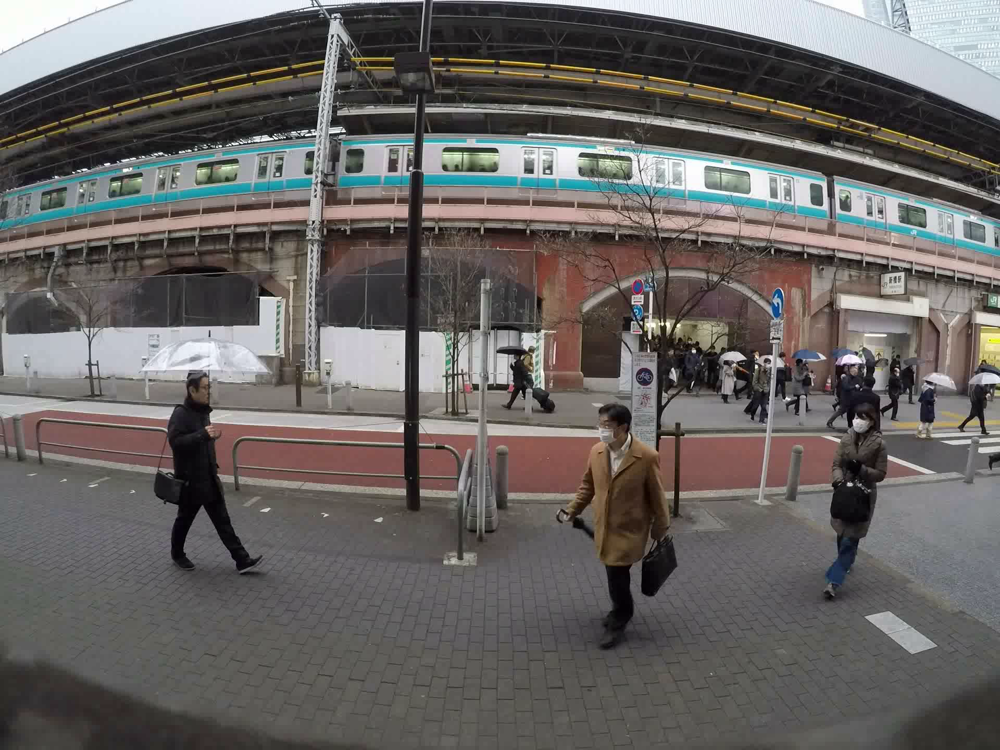

--- フレーム 1 (shape: (1440, 1920, 3)) ---


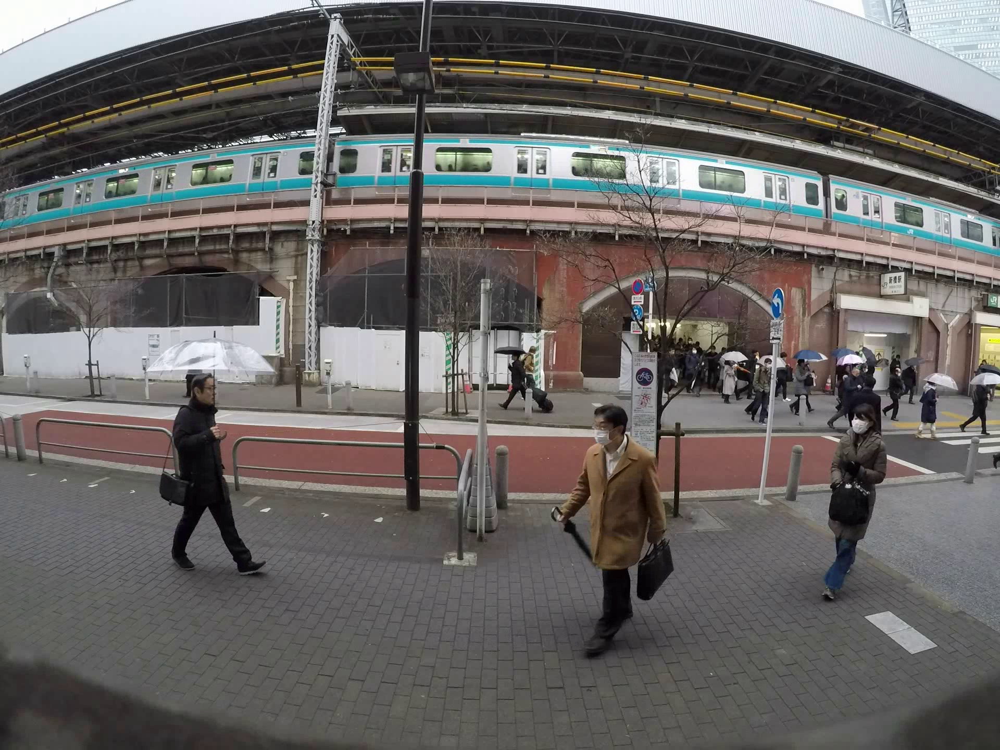

--- フレーム 2 (shape: (1440, 1920, 3)) ---


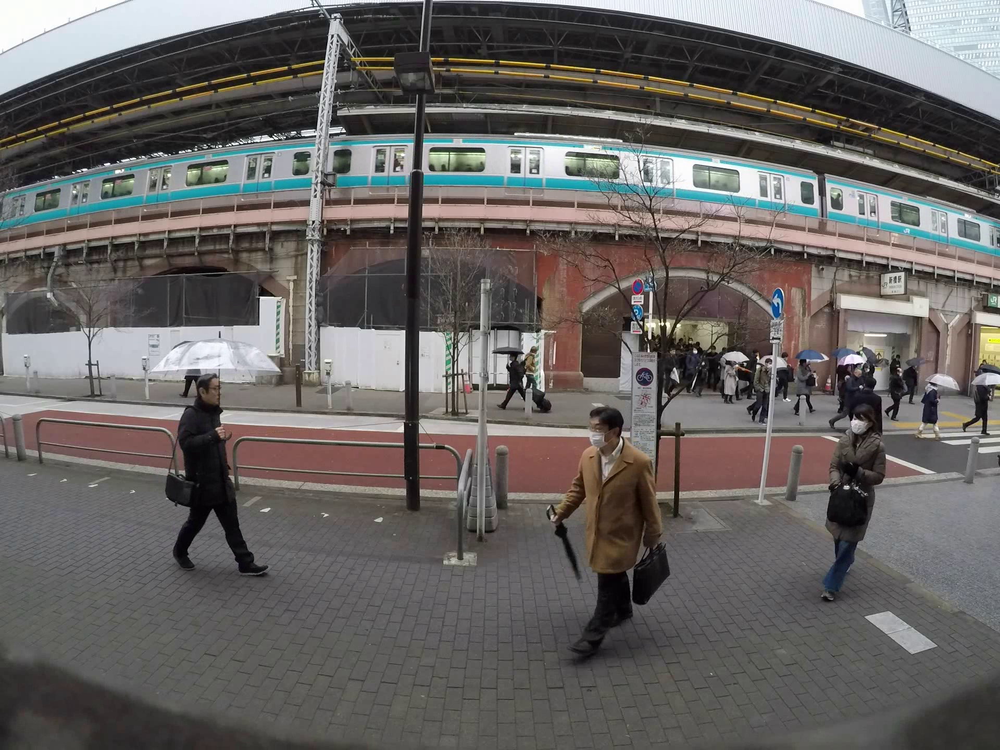

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# 9章のデータがあるフォルダへ移動する
import os
os.chdir('/content/drive/MyDrive/Colab Notebooks/16_python-100-knocks/100knocks_download/サンプルコード_20201021/9章/')

import cv2

# Colab専用の画像表示関数をインポート
from google.colab.patches import cv2_imshow

# 動画の保存場所にパスを通す
video_path = "mov/mov01.avi"
cap = cv2.VideoCapture(video_path)

# 動画が正しく開けたか確認
if not cap.isOpened():
  print("動画ファイルが開けませんでした。パスを確認してください。")
else:
  print("動画の読み込みに成功しました！")

# 最初の3フレーム（3枚の画像）だけをパラパラマンガから取り出して表示してみる
# 1枚分の画像を読み込む（retは成功フラグ、frameが画像データ）

  for i in range(3):
    ret, frame = cap.read()

    if ret:
      print(f"--- フレーム {i} (shape: {frame.shape}) ---")

# matplotlibの時はRGBに変換が必要でしたが、cv2_imshowならBGRのまま綺麗に表示できる
      cv2_imshow(frame)

    else:
      break

# 3. 後片付け、最後に必ず動画ファイルを解放する（超重要）
cap.release()

## 出力が重いとGitHubにアップロードできない

* [編集]→[出力をすべて消去]
* [ファイル]→[GitHubにコピーを保存]